# Ensemble of the seven single-fragment sequence runs on straightened2

Each `seq_<fragment>` model (trained on one 0846A fragment only, `models/runs_sequence/seq_<id>/final.pth`) predicts straightened2 with a flat depth-13 surface and window offset -1, as in `0846A_eval.ipynb`. Every map is stretched to its own p1-p99.5; the ensemble is the mean of the per-model z-scores. Same machinery as `ensemble_eval.ipynb`; outputs go to `output/ensemble/seq_fragments/<sheet>/`.

In [1]:
from pathlib import Path

# ---- sheets: name -> render zarr / mask id, and the flat-alias id (cached normalisation, stored cue map) -----------------------
SHEETS = {
    "auto_grown_20261012065803387_straightened2_abf": {"zid": "20261012065814", "norm_id": 20261012065815},
}

# ---- models: name -> settings ------------------------------------------------------------------------------------------
V8IN_RUN = Path("/vesuvius/nader-fork/runs/v8in_0846a_343/runs/v8in_0846a_343_6ep_20261021_013010_b2baf481/checkpoints")
MODELS = {
    "seq 20260927134931": {"kind": "iter2", "checkpoint": "/vesuvius/models/runs_sequence/seq_20260927134931/final.pth", "depth_offset": -1, "infer_batch": 4},
    "seq 20261012065813": {"kind": "iter2", "checkpoint": "/vesuvius/models/runs_sequence/seq_20261012065813/final.pth", "depth_offset": -1, "infer_batch": 4},
    "seq 20261012065817": {"kind": "iter2", "checkpoint": "/vesuvius/models/runs_sequence/seq_20261012065817/final.pth", "depth_offset": -1, "infer_batch": 4},
    "seq 20261012065819": {"kind": "iter2", "checkpoint": "/vesuvius/models/runs_sequence/seq_20261012065819/final.pth", "depth_offset": -1, "infer_batch": 4},
    "seq 20261012065821": {"kind": "iter2", "checkpoint": "/vesuvius/models/runs_sequence/seq_20261012065821/final.pth", "depth_offset": -1, "infer_batch": 4},
    "seq 20261012065823": {"kind": "iter2", "checkpoint": "/vesuvius/models/runs_sequence/seq_20261012065823/final.pth", "depth_offset": -1, "infer_batch": 4},
    "seq 20261012073246": {"kind": "iter2", "checkpoint": "/vesuvius/models/runs_sequence/seq_20261012073246/final.pth", "depth_offset": -1, "infer_batch": 4},
}

# ---- scoring ----------------------------------------------------------------------------------------------------------
SCORING = "z-score"      # 'z-score' | 'mean' | 'rank'  (see SCORING_METHODS below)
STRETCH = (1.0, 99.5)    # percentiles of each model's map over the sheet mask

FLAT_DEPTH = 13
EVAL_STRIDE = 32         # iter2 inference stride (px)
PREVIEW_DOWNSCALE = 10   # the saved figure stays full size
GRID_COLS = 4            # panels per row of the saved grid (the models, then the ensemble)
OUTPUT_SUBDIR = "seq_fragments" # output/ensemble/<OUTPUT_SUBDIR>/<sheet>/ ; set to keep a second set of runs apart

In [2]:
import gc
import os
import subprocess
import sys
import types

import cv2
import numpy as np
import torch
import zarr
from IPython.display import display
from PIL import Image

REPO = Path("/vesuvius")
# nonml_ink.py (imported by utils.precomputed_asf) lives in old/
for _path in (REPO, REPO / "old"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))
os.chdir(REPO)
Image.MAX_IMAGE_PIXELS = None

from utils.fast_figure import colorize, orient_display, save_panel_grid

ENSEMBLE_ROOT = REPO / "output" / "ensemble" / OUTPUT_SUBDIR
MODEL_CACHE = ENSEMBLE_ROOT / "_models"   # exported v8-in checkpoints, shared by all sheets


def slug(text):
    return "".join(ch if ch.isalnum() else "_" for ch in text).strip("_")


class Sheet:
    def __init__(self, name):
        spec = SHEETS[name]
        self.name, self.zid, self.norm_id = name, spec["zid"], spec["norm_id"]
        self.zarr_path = REPO / "ves_zarrs2" / f"{self.zid}.zarr"
        self.out_dir = ENSEMBLE_ROOT / name
        self.cache = self.out_dir / "cache"
        self.cache.mkdir(parents=True, exist_ok=True)
        self.mask = cv2.imread(str(REPO / "masks" / f"{self.zid}.png"), cv2.IMREAD_GRAYSCALE) > 0
        self.frame = self.mask.shape

    def to_frame(self, array):
        # map of any extent -> float32 frame, NaN outside the sheet mask
        out = np.full(self.frame, np.nan, np.float32)
        rows, cols = min(self.frame[0], array.shape[0]), min(self.frame[1], array.shape[1])
        out[:rows, :cols] = array[:rows, :cols]
        out[~self.mask] = np.nan
        return out

In [3]:
# ---- v8-in: runs in nader-fork's virtualenv (it needs safetensors); the central 24 layers of the sheet are its input ----------
FORK = REPO / "nader-fork"
V8IN_PREDICT = '''
import sys
import numpy as np
sys.path.insert(0, sys.argv[1])
from ink8um import InkDetector, predict_surface
model = InkDetector.from_pretrained(sys.argv[2])
prediction = predict_surface(model, sys.argv[3], reverse=model.reverse_layers, batch_size=int(sys.argv[5]))
np.save(sys.argv[4], prediction.astype(np.float16))
'''


def v8in_layers(sheet):
    existing = FORK / "runs" / "v8in_0846a_343" / "data_vis" / sheet.name / "layers"
    if (existing / "23.tif").is_file():
        return existing
    import tifffile

    folder = sheet.cache / "v8in_layers"
    folder.mkdir(exist_ok=True)
    volume = zarr.open(str(sheet.zarr_path), mode="r")
    start = (volume.shape[0] - 24) // 2
    for index in range(24):
        path = folder / f"{index:02d}.tif"
        if not path.is_file():
            tifffile.imwrite(path, np.clip(np.asarray(volume[start + index]), 0, 255).astype(np.uint8))
    return folder


def run_v8in(sheet, name, spec):
    prediction_path = sheet.cache / f"{slug(name)}.npy"
    if not prediction_path.is_file():
        python = str(FORK / ".venv" / "bin" / "python")
        model_dir = MODEL_CACHE / slug(name)
        if not (model_dir / "model.safetensors").is_file():
            subprocess.run([python, str(FORK / "training" / "export_checkpoint.py"), str(spec["checkpoint"]), str(model_dir)], check=True)
        subprocess.run([python, "-c", V8IN_PREDICT, str(FORK), str(model_dir), str(v8in_layers(sheet)), str(prediction_path),
                        str(spec.get("batch_size", 4))], check=True)
    return np.load(prediction_path).astype(np.float32)


# ---- reader-v2: the team's inference CLI in reader-v2's virtualenv (default centred 17-layer window, hann blend, overlap 0.5) --
def run_reader_v2(sheet, name, spec):
    tif = sheet.cache / f"{slug(name)}.tif"
    folder = REPO / "reader-v2"
    python = str(folder / ".venv" / "bin" / "python")
    if not tif.is_file():
        subprocess.run([python, "-m", "koine_machines.inference.infer", str(sheet.zarr_path), str(spec["checkpoint"]), str(tif),
                        "--overlap", "0.5", "--blend-mode", "hann", "--direction", "forward", "--no-compile"], cwd=folder, check=True)
    # the CLI writes an LZW tiff; imagecodecs lives in reader-v2's environment, so the uint8 map is converted to .npy there
    npy = tif.with_suffix(".npy")
    if not npy.is_file():
        subprocess.run([python, "-c", "import sys, numpy as np, tifffile; np.save(sys.argv[2], tifffile.imread(sys.argv[1]))",
                        str(tif), str(npy)], check=True)
    return np.load(npy).astype(np.float32) / 255.0


# ---- iter2 model: in this kernel, replaying the checkpoint's run config as 0846A_eval.ipynb does ------------------------------
def run_iter2(sheet, name, spec):
    path = sheet.cache / f"{slug(name)}.npz"
    if not path.is_file():
        from utils.config import Config, ScrollConfig, resolve_run_config
        from utils.model import create_model
        from utils.norm import UNIFIED_CACHE_PATH, load_cached_norm
        from utils.platform import get_zarr_dir
        from utils.visualizer import TensorboardVisualizer, predict_tiles

        checkpoint = Path(spec["checkpoint"]).resolve()
        run_config, _ = resolve_run_config(checkpoint)
        C = Config()
        for section in ("data", "model"):
            for key, value in run_config[section].items():
                if section == "data" and key == "scrolls":
                    C.data.scrolls = [ScrollConfig(**item) for item in value]
                elif key != "probe_rois" and hasattr(getattr(C, section), key):
                    setattr(getattr(C, section), key, value)
        C.model.compile_model = False
        C.tra.supcon = False
        C.tra.dann = False
        C.device = "cuda" if torch.cuda.is_available() else "cpu"
        C.data.eval_stride = EVAL_STRIDE
        C.data.eval_infer_bs = int(spec.get("infer_batch", 0))  # 0 = automatic; a small value saves VRAM, results are identical
        offset = int(spec.get("depth_offset", -1))
        C.data.surface_window_offset = offset
        C.data.surface_window_offset_by_scroll = {}
        C.data.zarr_path = str(Path(get_zarr_dir()))
        depth = int(C.data.depth)
        if depth != 8 or not C.model.surface_teacher_input or not C.data.surface_relative_depth_window:
            raise ValueError("Select a literal-surface, eight-slice checkpoint")
        model, _ = create_model(C)
        state = torch.load(checkpoint, map_location="cpu", weights_only=True)
        state = state.get("model_state_dict", state.get("state_dict", state))
        state = {key.removeprefix("module.").removeprefix("_orig_mod."): value for key, value in state.items()}
        state = {key: value for key, value in state.items() if not key.startswith(("supcon_head.", "domain_head."))}
        model.load_state_dict(state, strict=True)
        model.eval()

        volume = np.ascontiguousarray(zarr.open(str(sheet.zarr_path), mode="r")[:])
        volume.setflags(write=False)
        height, width = sheet.mask.shape
        surface_depth = np.where(sheet.mask, FLAT_DEPTH, 255).astype(np.uint8)
        surface_confidence = np.where(sheet.mask, 255, 0).astype(np.uint8)
        norm = load_cached_norm(sheet.norm_id, UNIFIED_CACHE_PATH, mode=str(C.data.norm_mode))
        if norm is None:
            raise RuntimeError(f"no cached normalisation for {sheet.norm_id}")
        cue = None
        if str(C.model.input_cue) == "pre_clahe":
            cue = np.load(Path(C.data.cue_dir) / f"{sheet.norm_id}.npy", mmap_mode="r")
        coords = TensorboardVisualizer._gen_tile_coords(
            types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end), (0, height), (0, width), sheet.mask, z_step=depth,
        )
        grid = predict_tiles(
            C, model, volume, sheet.mask, coords, (0, height), (0, width), C.data.d_start, sheet.name, *norm,
            surface_depth_map=surface_depth, surface_confidence_map=surface_confidence,
            surface_depth_offset=offset, cue_map=cue,
        )
        np.savez(path, grid=np.asarray(grid, dtype=np.float32), cell=int(C.model.multitile_subtile))
        del model, volume
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    saved = np.load(path)
    cell = int(saved["cell"])
    return np.repeat(np.repeat(saved["grid"], cell, axis=0), cell, axis=1)


RUNNERS = {"v8in": run_v8in, "reader_v2": run_reader_v2, "iter2": run_iter2}

In [4]:
# ---- stretching and scoring ----------------------------------------------------------------------------------------------
def stretch(prediction, mask):
    valid = mask & np.isfinite(prediction)
    low, high = np.percentile(prediction[valid], STRETCH)
    stretched = np.clip((prediction - low) / max(float(high - low), 1e-6), 0, 1)
    return np.where(valid, stretched, np.nan).astype(np.float32), float(low), float(high)


def z_score(values):
    valid = np.isfinite(values)
    return ((values - values[valid].mean()) / max(float(values[valid].std()), 1e-6)).astype(np.float32)


def rank_score(values):
    valid = np.isfinite(values)
    ranks = np.full(values.shape, np.nan, np.float32)
    order = np.argsort(values[valid], kind="stable")
    scores = np.empty(order.size, np.float32)
    scores[order] = np.linspace(0, 1, order.size, dtype=np.float32)
    ranks[valid] = scores
    return ranks


# stretched maps (list) -> ensemble map; every method returns NaN outside the sheet
SCORING_METHODS = {
    "z-score": lambda maps: np.mean([z_score(m) for m in maps], axis=0),
    "mean": lambda maps: np.mean(maps, axis=0),
    "rank": lambda maps: np.mean([rank_score(m) for m in maps], axis=0),
}
if SCORING not in SCORING_METHODS:
    raise ValueError(f"SCORING must be one of {sorted(SCORING_METHODS)}")


def run_ensemble(sheet_name):
    # run every model on the sheet, stretch, combine, save the 2x2 grid at full resolution, show it at 1/10
    sheet = Sheet(sheet_name)
    print(f"{sheet.name}: frame {sheet.frame}, {int(sheet.mask.sum()):,} papyrus pixels; cache {sheet.cache}")
    stretched, limits = {}, {}
    for name, spec in MODELS.items():
        print(f"[{spec['kind']}] {name}")
        stretched[name], low, high = stretch(sheet.to_frame(RUNNERS[spec["kind"]](sheet, name, spec)), sheet.mask)
        limits[name] = (low, high)
        print(f"    p{STRETCH[0]:g} {low:.4f}, p{STRETCH[1]:g} {high:.4f}")
        gc.collect()

    ensemble = SCORING_METHODS[SCORING](list(stretched.values()))
    valid = np.isfinite(ensemble)
    e_low, e_high = np.percentile(ensemble[valid], STRETCH)
    print(f"ensemble ({SCORING}): p{STRETCH[0]:g} {e_low:.3f}, p{STRETCH[1]:g} {e_high:.3f}")

    bad = (0.78, 0.86, 0.95)
    panels = [
        (f"{name} | stretched p{STRETCH[0]:g}-p{STRETCH[1]:g} ({limits[name][0]:.3f}..{limits[name][1]:.3f})",
         colorize(orient_display(array, sheet.name), "gray_r", bad), cv2.INTER_AREA, None)
        for name, array in stretched.items()
    ]
    panels.append((f"ensemble | mean of per-model {SCORING}s, shown p{STRETCH[0]:g}-p{STRETCH[1]:g}",
                   colorize(orient_display(ensemble, sheet.name), "gray_r", bad, vmin=float(e_low), vmax=float(e_high)),
                   cv2.INTER_AREA, None))
    cell_hw = orient_display(ensemble, sheet.name).shape

    rows = [panels[i:i + GRID_COLS] for i in range(0, len(panels), GRID_COLS)]
    grid_path = sheet.out_dir / f"ensemble_{slug(SCORING)}_{len(rows)}x{GRID_COLS}.png"
    save_panel_grid(rows, cell_hw, str(grid_path), gap_px=24)
    np.save(sheet.out_dir / f"ensemble_{slug(SCORING)}.npy", ensemble.astype(np.float16))
    print(f"Saved {grid_path}")
    with Image.open(grid_path) as saved:
        print("full size", saved.size)
        display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                             Image.Resampling.LANCZOS))
    del stretched, ensemble, panels
    gc.collect()
    return grid_path

auto_grown_20261012065803387_straightened2_abf: frame (2561, 4101), 7,602,644 papyrus pixels; cache /vesuvius/output/ensemble/seq_fragments/auto_grown_20261012065803387_straightened2_abf/cache
[iter2] seq 20260927134931


2026-10-21 23:37:43.878378: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-21 23:37:43.879988: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-21 23:37:43.883135: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-21 23:37:43.891260: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792625863.904313  936587 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792625863.90

Model parameters (nnunet3d_lcndz): 7,554,654


/usr/local/lib/python3.10/dist-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


...

[predict] auto_grown_20261012065803387_straightened2_abf done in  73.9s  predict  71.9s (97.3%)  read/wait   2.0s ( 2.7%)  [prefetch x3]
    p1 0.0030, p99.5 0.7797
[iter2] seq 20261012065823
Model parameters (nnunet3d_lcndz): 7,554,654
[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


Read auto_grown_20261012065803387_straightened2_abf:  28%|██▊       | 19/69 [00:00<00:01, 34.15it/s]
Predict chunk: 100%|█████████▉| 424/426 [00:16<00:00, 27.36it/s]
Read auto_grown_20261012065803387_straightened2_abf:  49%|████▉     | 34/69 [00:17<00:14,  2.41it/s]
Predict chunk:  73%|███████▎  | 327/449 [00:12<00:04, 26.87it/s]
Read auto_grown_20261012065803387_straightened2_abf:  49%|████▉     | 34/69 [00:29<00:14,  2.41it/s]
Predict chunk: 100%|██████████| 449/449 [00:17<00:00, 26.92it/s]
Read auto_grown_20261012065803387_straightened2_abf:  70%|██████▉   | 48/69 [00:34<00:10,  1.93it/s]
Predict chunk:  89%|████████▊ | 390/440 [00:14<00:01, 25.81it/s]
Read auto_grown_20261012065803387_straightened2_abf:  70%|██████▉   | 48/69 [00:49<00:10,  1.93it/s]
Predict chunk: 100%|█████████▉| 439/440 [00:16<00:00, 25.87it/s]
Read auto_grown_20261012065803387_straightened2_abf:  88%|████████▊ | 61/69 [00:52<00:05,  1.58it/s]
Predict chunk: 100%|██████████| 438/438 [00:16<00:00, 26.30it/s]


[predict] auto_grown_20261012065803387_straightened2_abf done in  73.8s  predict  71.8s (97.3%)  read/wait   2.0s ( 2.7%)  [prefetch x3]
    p1 0.0003, p99.5 0.9851
[iter2] seq 20261012073246
Model parameters (nnunet3d_lcndz): 7,554,654
[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


Read auto_grown_20261012065803387_straightened2_abf:  26%|██▌       | 18/69 [00:00<00:01, 32.45it/s]
Predict chunk:  81%|████████  | 345/426 [00:13<00:03, 26.02it/s]
Read auto_grown_20261012065803387_straightened2_abf:  28%|██▊       | 19/69 [00:13<00:01, 32.45it/s]
Predict chunk:  99%|█████████▉| 423/426 [00:16<00:00, 26.10it/s]
Read auto_grown_20261012065803387_straightened2_abf:  49%|████▉     | 34/69 [00:17<00:15,  2.25it/s]
Predict chunk:  96%|█████████▋| 433/449 [00:16<00:00, 25.93it/s]
Read auto_grown_20261012065803387_straightened2_abf:  49%|████▉     | 34/69 [00:33<00:15,  2.25it/s]
Predict chunk: 100%|█████████▉| 448/449 [00:17<00:00, 26.85it/s]
Read auto_grown_20261012065803387_straightened2_abf:  68%|██████▊   | 47/69 [00:34<00:13,  1.62it/s]
Predict chunk: 100%|█████████▉| 439/440 [00:16<00:00, 26.69it/s]
Read auto_grown_20261012065803387_straightened2_abf:  87%|████████▋ | 60/69 [00:51<00:06,  1.41it/s]
Predict chunk:  79%|███████▉  | 346/438 [00:11<00:03, 26.10it/s]
Read

[predict] auto_grown_20261012065803387_straightened2_abf done in  72.1s  predict  70.1s (97.3%)  read/wait   1.9s ( 2.7%)  [prefetch x3]
    p1 0.0012, p99.5 0.9690
ensemble (z-score): p1 -0.935, p99.5 2.913
Saved /vesuvius/output/ensemble/seq_fragments/auto_grown_20261012065803387_straightened2_abf/ensemble_z_score_2x4.png
full size (16914, 5792)


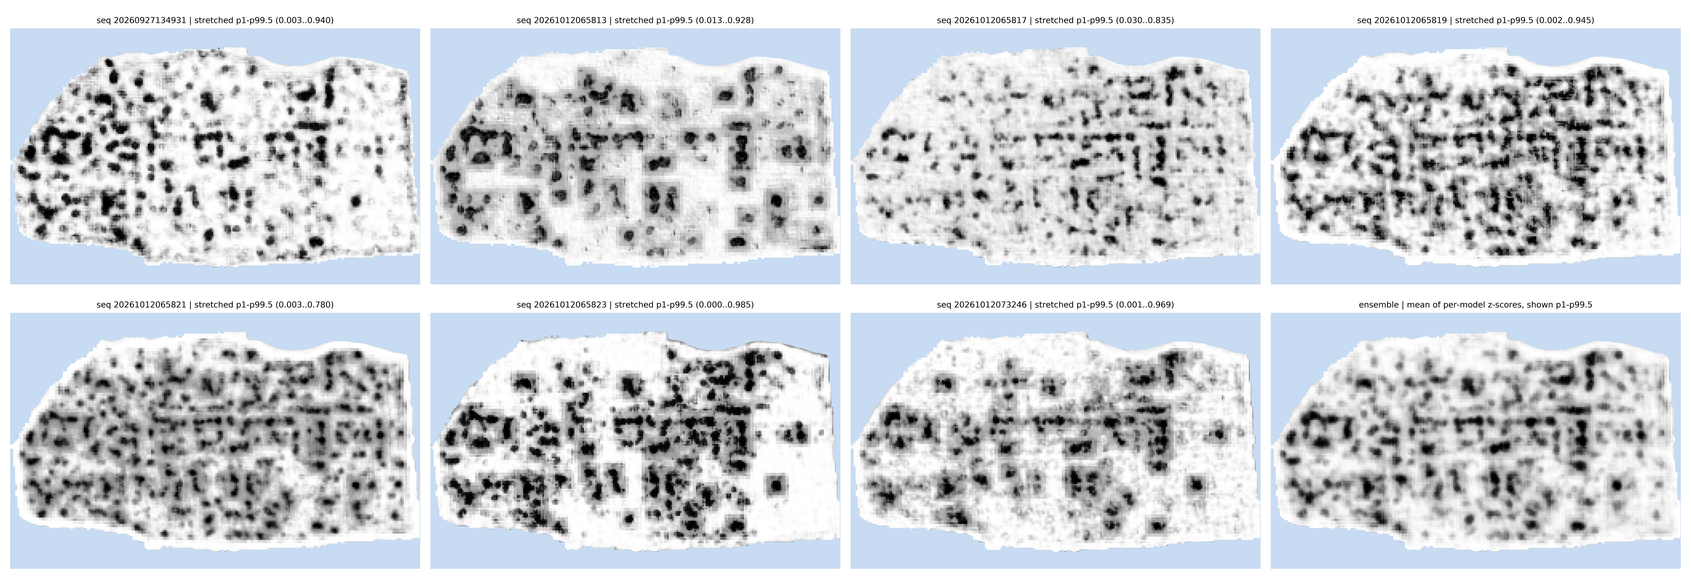

In [5]:
seq_path = run_ensemble("auto_grown_20261012065803387_straightened2_abf")